In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ==========================
# 0. Imports and config
# ==========================
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [3]:
# ==========================
# 1. Load data
# ==========================
file_path = "../data/Compressive_Strength.xlsx"  # UCI CS corpus (n=1030); same records as Concrete_Data.xlsx
df = pd.read_excel(file_path)

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.head()

Shape: (1030, 9)

Columns: ['Cement', 'Slag', 'FA', 'Water', 'SP', 'NCA', 'NFA', 'Age', 'CS']


,Cement,Slag,FA,Water,SP,NCA,NFA,Age,CS
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [4]:
# Basic info
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Cement  1030 non-null   float64
 1   Slag    1030 non-null   float64
 2   FA      1030 non-null   float64
 3   Water   1030 non-null   float64
 4   SP      1030 non-null   float64
 5   NCA     1030 non-null   float64
 6   NFA     1030 non-null   float64
 7   Age     1030 non-null   int64  
 8   CS      1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
Slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
FA,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
Water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
SP,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
NCA,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
NFA,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
Age,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
CS,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


In [5]:
# ==========================
# 2. Target and feature engineering
# ==========================

TARGET_COL = "CS"

y = df[TARGET_COL].values
X = df.drop(columns=[TARGET_COL]).copy()

print("Original feature columns:", X.columns.tolist())

# --- Feature engineering ---
X_fe = X.copy()
cols = X_fe.columns

def has(*names):
    return all(name in cols for name in names)

# w/c ratio
if has("Water", "Cement"):
    X_fe["w_c"] = X_fe["Water"] / (X_fe["Cement"] + 1e-9)

# Binder, w/b, SCM fraction
if has("Water", "Cement", "Slag", "FA"):
    X_fe["Binder"] = X_fe[["Cement", "Slag", "FA"]].sum(axis=1)
    X_fe["w_b"] = X_fe["Water"] / (X_fe["Binder"] + 1e-9)
    X_fe["SCM_frac"] = X_fe[["Slag", "FA"]].sum(axis=1) / (X_fe["Binder"] + 1e-9)

# Aggregates
if has("NCA", "NFA"):
    X_fe["Agg_total"] = X_fe["NCA"] + X_fe["NFA"]
    if "Binder" in X_fe.columns:
        X_fe["Agg_to_Binder"] = X_fe["Agg_total"] / (X_fe["Binder"] + 1e-9)

# Superplasticizer relative to binder
if has("SP",) and "Binder" in X_fe.columns:
    X_fe["SP_per_binder"] = X_fe["SP"] / (X_fe["Binder"] + 1e-9)

# Simple interaction term
if has("Water", "SP"):
    X_fe["Water_SP"] = X_fe["Water"] * X_fe["SP"]

print("Feature columns after engineering:", X_fe.columns.tolist())
print("Final feature shape:", X_fe.shape)


Original feature columns: ['Cement', 'Slag', 'FA', 'Water', 'SP', 'NCA', 'NFA', 'Age']
Feature columns after engineering: ['Cement', 'Slag', 'FA', 'Water', 'SP', 'NCA', 'NFA', 'Age', 'w_c', 'Binder', 'w_b', 'SCM_frac', 'Agg_total', 'Agg_to_Binder', 'SP_per_binder', 'Water_SP']
Final feature shape: (1030, 16)


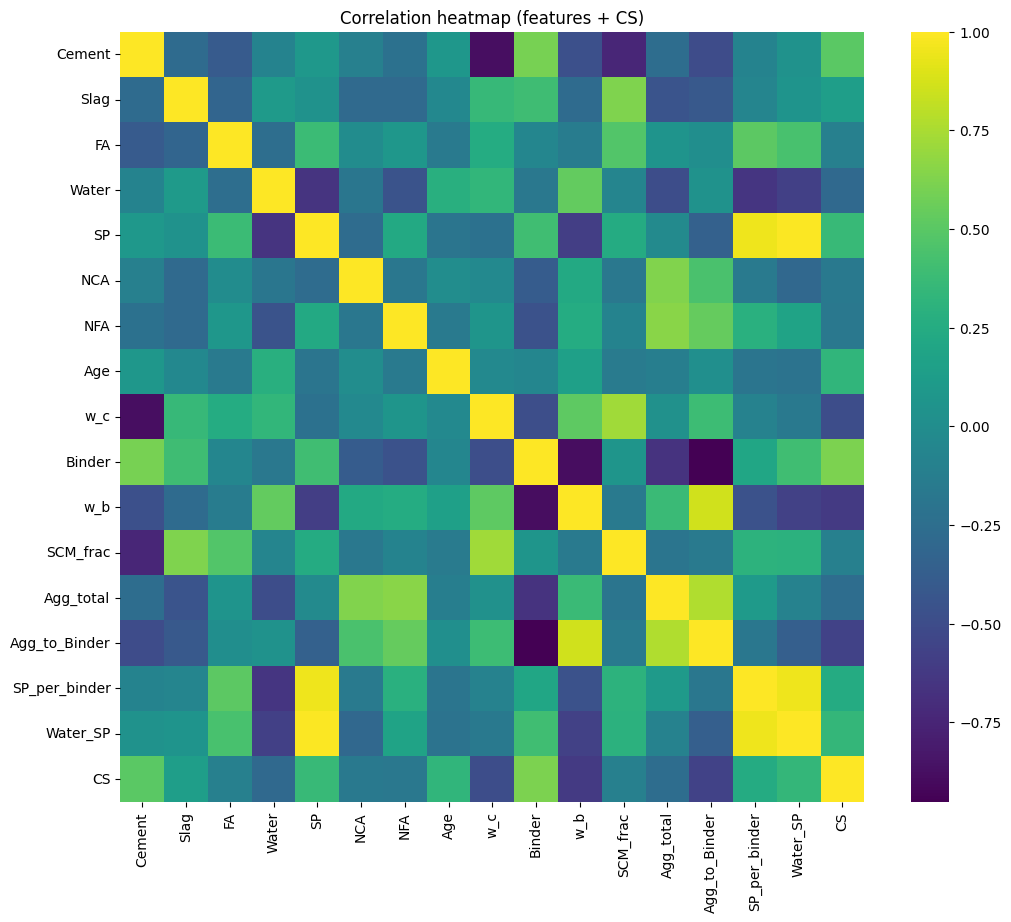

In [6]:
# Correlation heatmap
plt.figure(figsize=(12, 10))
corr = pd.DataFrame(X_fe).assign(CS=y).corr()
sns.heatmap(corr, annot=False, cmap="viridis")
plt.title("Correlation heatmap (features + CS)")
plt.show()


In [7]:
# ==========================
# 3. Train-test split
# ==========================
X_train, X_test, y_train, y_test = train_test_split(
    X_fe, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (824, 16)  Test shape: (206, 16)


In [8]:
# ==========================
# 4. Define models
# ==========================

models = {
    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=RANDOM_STATE))
    ]),
    "RandomForest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "GBR": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(
            n_neighbors=5,
            weights="distance"
        ))
    ]),
    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(C=10, epsilon=0.1, kernel="rbf"))
    ])
}

list(models.keys())


['LinearRegression',
 'Ridge',
 'RandomForest',
 'ExtraTrees',
 'GBR',
 'KNN',
 'SVR']

In [9]:
# ==========================
# 5. Cross-validation evaluation
# ==========================

def compute_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    return r2, mse, mae, rmse

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []

for name, model in models.items():
    print(f"Evaluating model: {name}")
    r2_list, mse_list, mae_list, rmse_list = [], [], [], []

    for train_idx, val_idx in cv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model.fit(X_tr, y_tr)
        y_val_pred = model.predict(X_val)

        r2, mse, mae, rmse = compute_metrics(y_val, y_val_pred)
        r2_list.append(r2)
        mse_list.append(mse)
        mae_list.append(mae)
        rmse_list.append(rmse)

    results.append({
        "Model": name,
        "R2_mean": np.mean(r2_list),
        "R2_std": np.std(r2_list),
        "MSE_mean": np.mean(mse_list),
        "MSE_std": np.std(mse_list),
        "RMSE_mean": np.mean(rmse_list),
        "RMSE_std": np.std(rmse_list),
        "MAE_mean": np.mean(mae_list),
        "MAE_std": np.std(mae_list)
    })

cv_results = pd.DataFrame(results).sort_values(by="R2_mean", ascending=False)
cv_results


Evaluating model: LinearRegression
Evaluating model: Ridge
Evaluating model: RandomForest
Evaluating model: ExtraTrees
Evaluating model: GBR
Evaluating model: KNN
Evaluating model: SVR


,Model,R2_mean,R2_std,MSE_mean,MSE_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std
3,ExtraTrees,0.911751,0.012350,24.879824,3.718768,4.973602,0.378299,3.170840,0.298701
4,GBR,0.910321,0.013637,25.255700,3.815235,5.011280,0.377856,3.596814,0.244531
2,RandomForest,0.902678,0.017036,27.439952,5.003156,5.216434,0.478294,3.611207,0.359550
6,SVR,0.788626,0.033271,59.533073,9.391751,7.691585,0.610407,5.642621,0.481668
5,KNN,0.709207,0.041015,81.958008,12.087943,9.028887,0.661222,6.559852,0.394178
1,Ridge,0.617845,0.038406,107.459315,8.982714,10.357108,0.435474,8.160666,0.314813
0,LinearRegression,0.617471,0.035910,107.597035,8.609837,10.364491,0.417577,8.185805,0.307971



Feature importance for ExtraTrees:


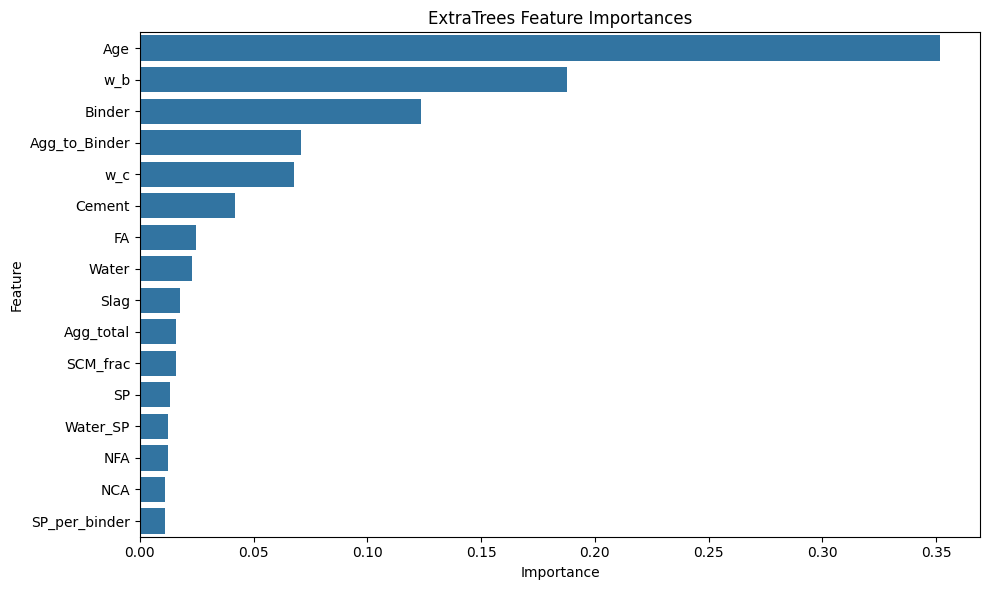


Feature importance for GBR:


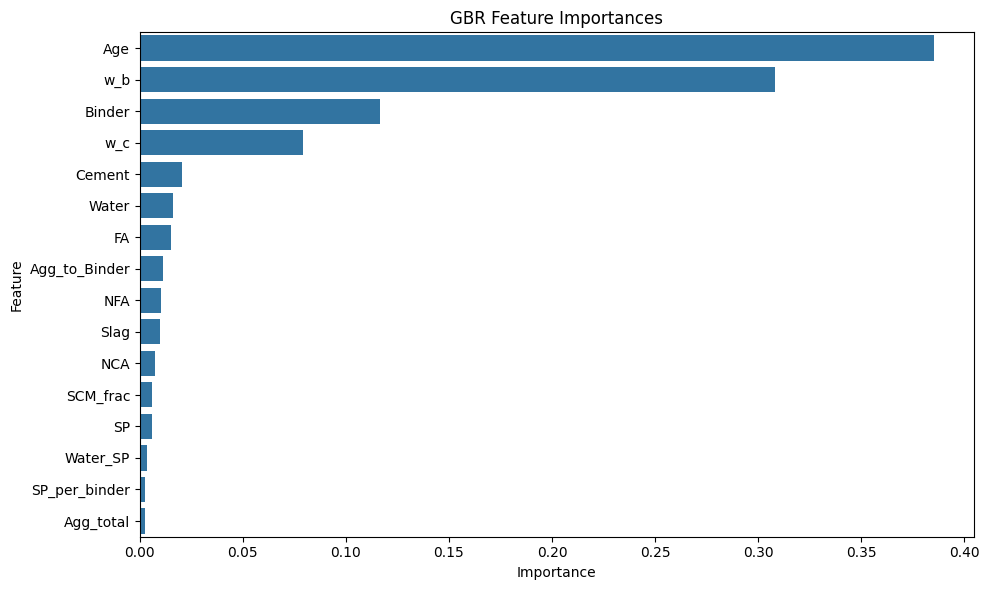

In [10]:
# ==========================
# 7. Feature importance (tree models)
# ==========================

def plot_feature_importance(model, feature_names, title):
    importances = model.feature_importances_
    idx = np.argsort(importances)[::-1]
    sorted_names = np.array(feature_names)[idx]
    sorted_importances = importances[idx]

    plt.figure(figsize=(10, 6))
    sns.barplot(x=sorted_importances, y=sorted_names)
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title(title)
    plt.tight_layout()
    plt.show()

# Fit tree models on full training data for importance plots
for tree_name in ["ExtraTrees", "GBR"]:
    tree_model = models[tree_name]
    tree_model.fit(X_train, y_train)
    print(f"\nFeature importance for {tree_name}:")
    plot_feature_importance(tree_model, X_train.columns.tolist(),
                            title=f"{tree_name} Feature Importances")


In [11]:
# ==========================
# 9. Hyperparameter tuning
# 9.1 Gradient Boosting Regressor
# ==========================

gbr = GradientBoostingRegressor(random_state=RANDOM_STATE)

param_dist_gbr = {
    "n_estimators": [100, 200, 300, 400],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "subsample": [0.8, 1.0],
    "min_samples_leaf": [1, 3, 5]
}

gbr_search = RandomizedSearchCV(
    estimator=gbr,
    param_distributions=param_dist_gbr,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

gbr_search.fit(X_train, y_train)
print("Best GBR params:", gbr_search.best_params_)
print("Best GBR CV R²:", gbr_search.best_score_)

# Evaluate tuned GBR on test set
gbr_best = gbr_search.best_estimator_
y_test_pred_gbr = gbr_best.predict(X_test)
r2_gbr, mse_gbr, mae_gbr, rmse_gbr = compute_metrics(y_test, y_test_pred_gbr)

print("\nTuned GBR Test performance:")
print(f"R²   = {r2_gbr:.4f}")
print(f"MSE  = {mse_gbr:.4f}")
print(f"RMSE = {rmse_gbr:.4f}")
print(f"MAE  = {mae_gbr:.4f}")


Best GBR params: {'subsample': 0.8, 'n_estimators': 400, 'min_samples_leaf': 3, 'max_depth': 3, 'learning_rate': 0.1}
Best GBR CV R²: 0.9309711724734567

Tuned GBR Test performance:
R²   = 0.9419
MSE  = 14.9696
RMSE = 3.8691
MAE  = 2.6696


In [12]:
# ==========================
# 9.2 ExtraTrees Regressor
# ==========================

etr = ExtraTreesRegressor(random_state=RANDOM_STATE)

param_dist_etr = {
    "n_estimators": [200, 400, 600],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 4, 6],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["auto", "sqrt", 0.7, 0.9]
}

etr_search = RandomizedSearchCV(
    estimator=etr,
    param_distributions=param_dist_etr,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

etr_search.fit(X_train, y_train)
print("Best ExtraTrees params:", etr_search.best_params_)
print("Best ExtraTrees CV R²:", etr_search.best_score_)

# Evaluate tuned ExtraTrees on test set
etr_best = etr_search.best_estimator_
y_test_pred_etr = etr_best.predict(X_test)
r2_etr, mse_etr, mae_etr, rmse_etr = compute_metrics(y_test, y_test_pred_etr)

print("\nTuned ExtraTrees Test performance:")
print(f"R²   = {r2_etr:.4f}")
print(f"MSE  = {mse_etr:.4f}")
print(f"RMSE = {rmse_etr:.4f}")
print(f"MAE  = {mae_etr:.4f}")


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
10 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.12/dist-packages/sklearn/utils/

Best ExtraTrees params: {'n_estimators': 600, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 20}
Best ExtraTrees CV R²: 0.9181816238973207

Tuned ExtraTrees Test performance:
R²   = 0.9074
MSE  = 23.8647
RMSE = 4.8852
MAE  = 3.2967


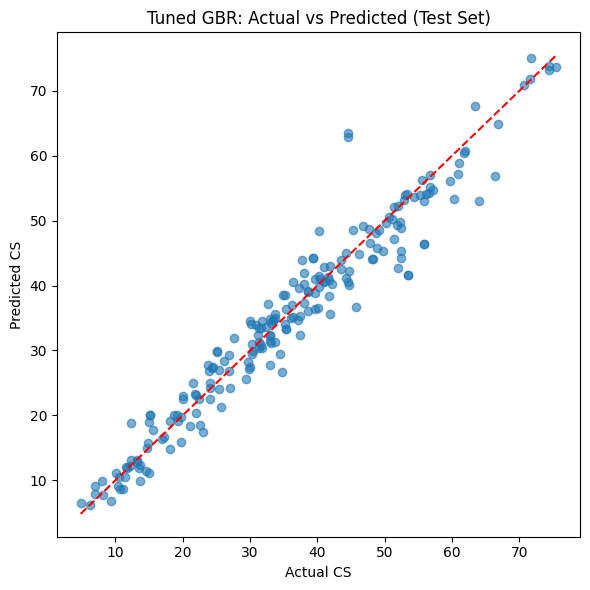

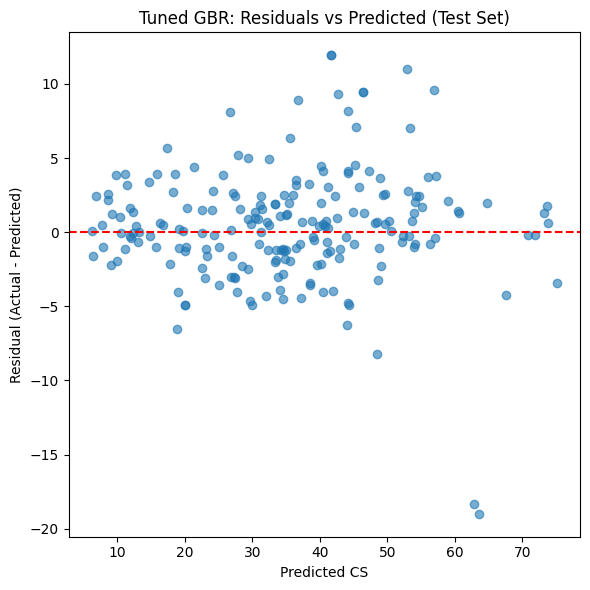

In [16]:
# ==========================
# 8. Residual analysis
# ==========================

y_pred = y_test_pred_gbr  # from best_model prediction
best_name = "Tuned GBR" # Define best_name

residuals = y_test - y_pred

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--')
plt.xlabel("Actual CS")
plt.ylabel("Predicted CS")
plt.title(f"{best_name}: Actual vs Predicted (Test Set)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel("Predicted CS")
plt.ylabel("Residual (Actual - Predicted)")
plt.title(f"{best_name}: Residuals vs Predicted (Test Set)")
plt.tight_layout()
plt.show()


--- SHAP Summary Plot ---


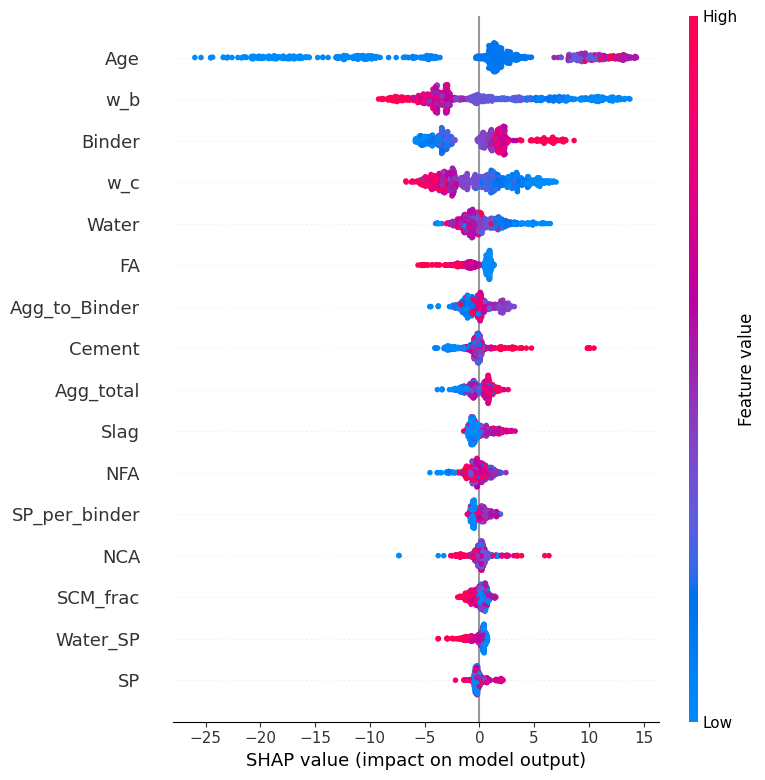


Top 5 features for Tuned GBR: ['Age', 'w_b', 'Binder', 'w_c', 'Water']

--- SHAP Dependence Plots for Top 5 Features ---


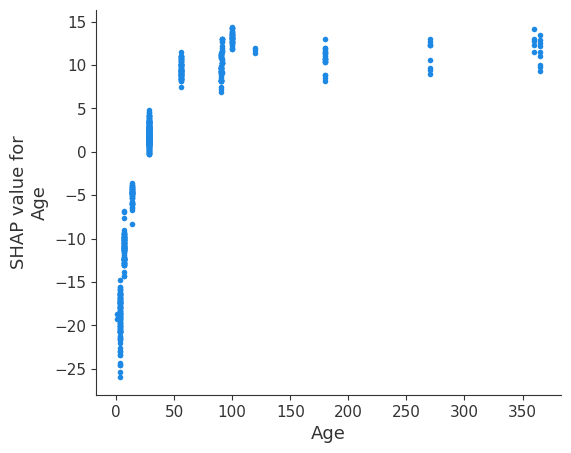

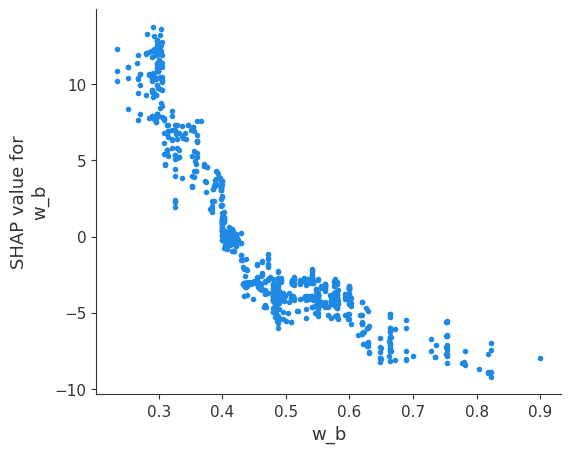

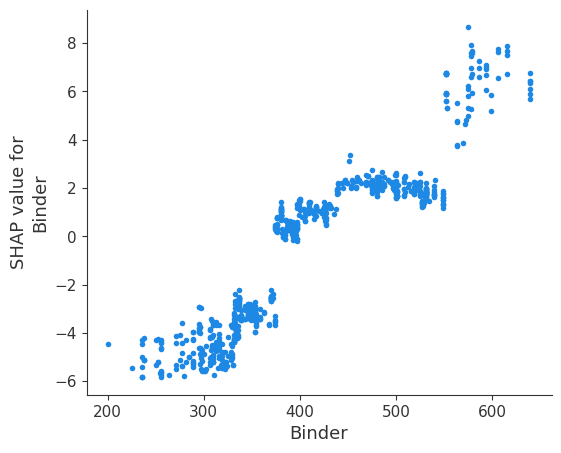

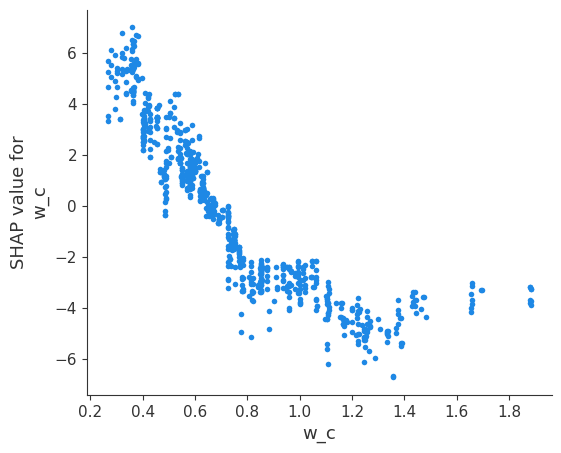

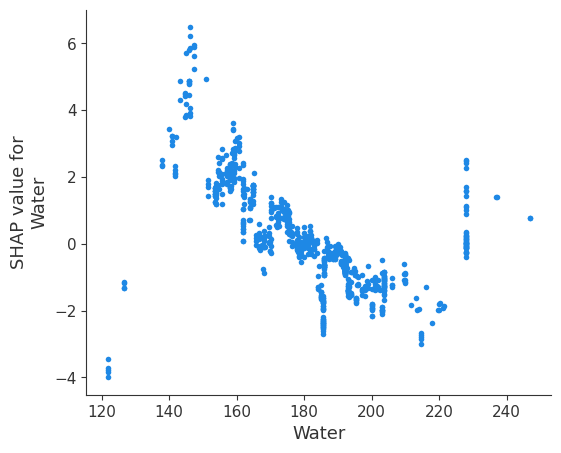

In [18]:
import shap # Ensure shap is imported, though it was earlier
import warnings

# Filter the specific FutureWarning related to NumPy's global RNG seeding
warnings.filterwarnings("ignore", category=FutureWarning, message="The NumPy global RNG was seeded by calling `np.random.seed`")

# Assign the best performing model and its name for SHAP analysis
best_model_for_shap = gbr_best  # From the best performing model in hyperparameter tuning
best_tuned_model_name = "Tuned GBR" # From the best performing model name

# Create a SHAP explainer for the best model
# Using 'shap.Explainer' for universal compatibility.
explainer = shap.Explainer(best_model_for_shap, X_train)

# Calculate SHAP values for the training data
shap_values = explainer(X_train)

# Summary plot (global importance + direction)
print("\n--- SHAP Summary Plot ---")
shap.summary_plot(shap_values, X_train, plot_type="dot")

# Identify top features from SHAP values
shap_values_array = shap_values.values
mean_abs_shap = np.abs(shap_values_array).mean(axis=0)
feature_order = np.argsort(mean_abs_shap)[::-1]
top_features = [X_train.columns[i] for i in feature_order]

print(f"\nTop {len(top_features[:5])} features for {best_tuned_model_name}: {top_features[:5]}")

# Dependence plots for the top 5 features
print("\n--- SHAP Dependence Plots for Top 5 Features ---")
for feature in top_features[:5]:
    shap.dependence_plot(feature, shap_values_array, X_train, interaction_index=None)